# Notebook 06: Open Questions

**Paper Reference:** Gould et al. (2013), Section 6 — *Key unresolved problems*

The first problem the paper lists is understanding statistical regularities: *"no single model has yet been capable of simultaneously reproducing all of the statistical regularities, and there is no clear picture about how the stylized facts emerge as a consequence of the actions of many heterogeneous traders."*

Simulation lets us probe this with **ablation studies**: start from the zero-intelligence model, add one ingredient at a time, and measure what changes. We explore four questions:

1. Which ingredients fatten the tails of the return distribution?
2. Can order splitting generate long memory in order signs?
3. When is price impact concave?
4. How does feedback between price moves and liquidity change the dynamics?

The simulation experiments use eight independent seeds per variant, run in parallel, and report the mean and standard error (SE) across seeds. Because we make many comparisons, a difference from the baseline counts as an effect only beyond 3 SE; between 2 and 3 SE we report it as tentative.

In [1]:
import os
import sys
import warnings
sys.path.insert(0, '..')

from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from lob.book import OrderBook
from lob.order import Side, limit_order, market_order, cancel_order, reset_order_id_counter
from lob.matching import PriceTimeEngine
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.hawkes import HawkesZIModel
from lob.models.long_memory import LongMemorySigns
from lob.metrics import event_time_returns
from lob.analysis.stylized_facts import (
    compute_acf, compute_hurst_rs, compute_rank_volatility_acf, fit_loglog_slope
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf

set_style()

ZI_PARAMS = dict(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000)
SEEDS = list(range(1, 9))
N_EVENTS = 300_000
K = 1_000  # events per return interval
findings = []  # computed conclusions, printed in the summary

# Seeds run in parallel worker processes. joblib's workers can run functions and
# classes defined in a notebook, which the standard library cannot on macOS.
N_JOBS = min(8, os.cpu_count() or 1)
# joblib restarts a worker whose memory has grown by 300 MB since its first task
# (each run allocates a few hundred MB that Python keeps for reuse) and warns when
# it does; no work is lost.
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")


def run_seed(make_model, extra, seed):
    """Run a model with one seed; return a dict of statistics."""
    reset_order_id_counter()
    model = make_model()
    df = Simulation(model=model, config=SimulationConfig(n_events=N_EVENTS, warmup_events=5_000, seed=seed)
                    ).run(progress=False)
    returns = event_time_returns(df['mid_price'], K)
    limits = df[df['event_type'] == 'limit']
    stats_ = {
        'returns': returns,
        'mean spread': df['spread'].mean(),
        'excess kurtosis': stats.kurtosis(returns),
        'rank ACF of |r|, lag 1': compute_rank_volatility_acf(returns, 1)[1],
        'ACF of r, lag 1': compute_acf(returns, 1)[1],
        'limit orders executing on arrival': (limits['n_fills'] > 0).mean(),
    }
    if extra is not None:
        stats_.update(extra(model, df))
    return stats_


def run_variant(make_model, extra=None):
    """Run a model over all seeds in parallel; return one dict of statistics per seed."""
    return Parallel(n_jobs=N_JOBS)(delayed(run_seed)(make_model, extra, seed) for seed in SEEDS)


def table(variants, columns):
    """Mean ± standard error across seeds for each variant and statistic."""
    rows = {}
    for name, runs in variants.items():
        rows[name] = {}
        for col in columns:
            values = np.array([r[col] for r in runs], dtype=float)
            rows[name][col] = f"{values.mean():.3f} ± {values.std(ddof=1) / np.sqrt(len(values)):.3f}"
    return pd.DataFrame(rows).T


def compare(variants, baseline, column, label):
    """Print how each variant changes one statistic relative to the baseline."""
    base = np.array([r[column] for r in variants[baseline]], dtype=float)
    lines = []
    for name, runs in variants.items():
        if name == baseline:
            continue
        x = np.array([r[column] for r in runs], dtype=float)
        diff = x.mean() - base.mean()
        se = np.sqrt(x.var(ddof=1) / len(x) + base.var(ddof=1) / len(base))
        direction = 'raises' if diff > 0 else 'lowers'
        if abs(diff) > 3 * se:
            call = direction
        elif abs(diff) > 2 * se:
            call = f'tentatively {direction}'
        else:
            call = 'does not significantly change'
        line = f"{name} {call} the {label} ({diff:+.3f} ± {se:.3f})"
        print(line)
        lines.append(line)
    return lines

## Question 1: Which Ingredients Fatten the Tails?

Section 4.7.1 of the paper reports heavy-tailed returns in a wide range of markets, and the literature offers several candidate causes. **Experiment:** start with the ZI model and add one ingredient at a time:

- **Heavy-tailed order sizes:** log-normal sizes for both limit and market orders.
- **Long-memory order signs:** buy/sell signs with Hurst exponent $H = 0.75$, shared by limit and market orders. They come from `LongMemorySigns`, a continuous long-memory stream (the signs of FARIMA noise) whose memory never resets.
- **Self-exciting market orders:** market orders arrive as a Hawkes process: each one raises the rate of further market orders, which decays back. Each triggers 0.8 more on average (the branching ratio), and the baseline rate is scaled down so the long-run rate of market orders is unchanged: only their clustering in time differs. Self-excitation is a form of feedback within the order flow itself.

The first two variants override the model's `_sample_side` / `_sample_size` hooks, so a limit order is always priced *after* its side is chosen: a buy still lands below the best ask. (Flipping the side after pricing would turn many limit orders into marketable ones and confound the experiment; the last column below checks that this does not happen.)

In [2]:
class ZIWithHeavySizes(SmithFarmerModel):
    """ZI model with log-normal sizes for limit and market orders."""

    def __init__(self, size_mean=1.0, size_sigma=1.0, **kwargs):
        super().__init__(**kwargs)
        self.size_mean = size_mean
        self.size_sigma = size_sigma

    def _sample_size(self, rng):
        return max(1, int(rng.lognormal(self.size_mean, self.size_sigma)))


class ZIWithLongMemorySigns(SmithFarmerModel):
    """ZI model whose buy/sell signs come from a continuous long-memory stream."""

    def __init__(self, hurst=0.75, **kwargs):
        super().__init__(**kwargs)
        self._signs = LongMemorySigns(hurst)

    def _sample_side(self, rng):
        return Side.BID if self._signs.next(rng) > 0 else Side.ASK


def sign_memory(model, df):
    signs = np.where(df.loc[df['event_type'] != 'cancel', 'side'] == 'bid', 1.0, -1.0)
    return {'sign ACF, lag 1': compute_acf(signs, 1)[1]}


ablation = {
    'Baseline ZI': run_variant(lambda: SmithFarmerModel(**ZI_PARAMS), sign_memory),
    '+ Heavy sizes': run_variant(lambda: ZIWithHeavySizes(**ZI_PARAMS), sign_memory),
    '+ Long-memory signs': run_variant(lambda: ZIWithLongMemorySigns(**ZI_PARAMS), sign_memory),
    '+ Self-exciting market orders': run_variant(
        lambda: HawkesZIModel(branching=0.8, decay=0.5, **ZI_PARAMS), sign_memory),
}
display(table(ablation, ['excess kurtosis', 'rank ACF of |r|, lag 1', 'sign ACF, lag 1',
                         'limit orders executing on arrival']))

,excess kurtosis,"rank ACF of |r|, lag 1","sign ACF, lag 1",limit orders executing on arrival
Baseline ZI,0.232 ± 0.118,0.030 ± 0.016,0.000 ± 0.001,0.000 ± 0.000
+ Heavy sizes,2.655 ± 0.535,0.043 ± 0.024,0.001 ± 0.001,0.000 ± 0.000
+ Long-memory signs,0.480 ± 0.103,0.041 ± 0.014,0.214 ± 0.001,0.000 ± 0.000
+ Self-exciting market orders,4.788 ± 0.828,0.252 ± 0.015,0.000 ± 0.001,0.000 ± 0.000


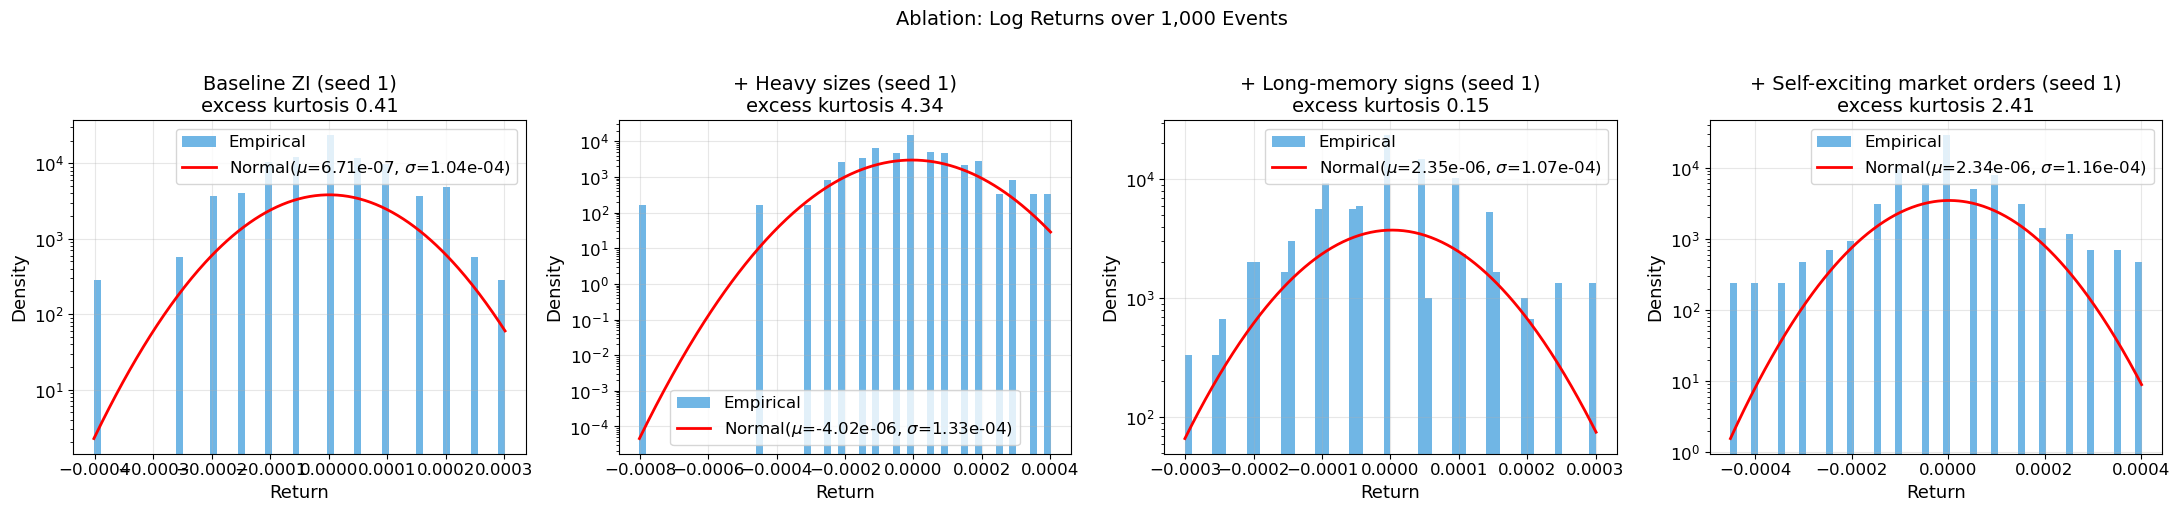

Relative to the baseline ZI model:
+ Heavy sizes raises the excess kurtosis (+2.423 ± 0.548)
+ Long-memory signs does not significantly change the excess kurtosis (+0.248 ± 0.156)
+ Self-exciting market orders raises the excess kurtosis (+4.556 ± 0.837)
+ Heavy sizes does not significantly change the volatility clustering (rank ACF) (+0.013 ± 0.029)
+ Long-memory signs does not significantly change the volatility clustering (rank ACF) (+0.011 ± 0.021)
+ Self-exciting market orders raises the volatility clustering (rank ACF) (+0.223 ± 0.022)


In [3]:
fig, axes = plt.subplots(1, len(ablation), figsize=(5.5 * len(ablation), 5))
for ax, (name, runs) in zip(axes, ablation.items(), strict=True):
    r = runs[0]['returns']
    plot_return_distribution(r, n_bins=60, ax=ax)
    ax.set_title(f'{name} (seed {SEEDS[0]})\nexcess kurtosis {stats.kurtosis(r):.2f}')
plt.suptitle(f'Ablation: Log Returns over {K:,} Events', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Relative to the baseline ZI model:")
findings += compare(ablation, 'Baseline ZI', 'excess kurtosis', 'excess kurtosis')
findings += compare(ablation, 'Baseline ZI', 'rank ACF of |r|, lag 1', 'volatility clustering (rank ACF)')

## Question 2: Can Order Splitting Generate Long Memory?

Section 4.7.3 of the paper reports long memory in the signs of incoming orders. A leading explanation is **order splitting**: large traders slice a big order into many small ones and submit them over time, so the same sign repeats in long runs.

**Experiment:** each trader arrives with a random sign and submits a run of child orders whose length has a power-law tail, $P(\text{length} > x) \sim x^{-\alpha}$ with $\alpha = 1.5$. For such runs, theory (Lillo, Mike and Farmer 2005) predicts sign autocorrelations decaying like $k^{-(\alpha - 1)}$, i.e. a Hurst exponent $H = (3 - \alpha)/2$.

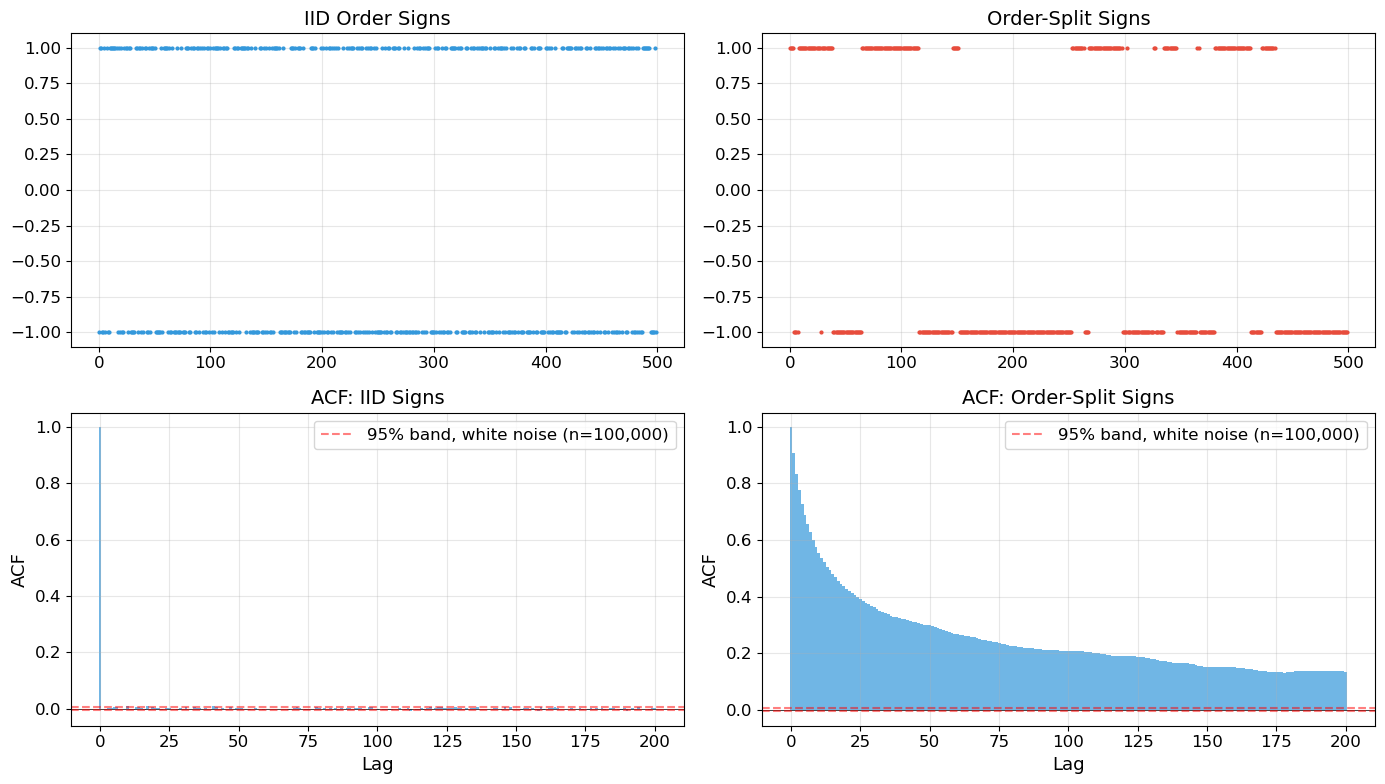

R/S Hurst exponent: IID signs 0.531, order-split signs 0.830 (theory 0.75)
ACF log-log slope over lags 5-100: -0.43 (theory -0.50)
Order splitting with power-law run lengths produces long memory close to the theory: ACF slope -0.43 vs -0.50, R/S H 0.83 vs 0.75


In [4]:
rng = np.random.default_rng(42)
alpha = 1.5
n = 100_000

iid_signs = rng.choice([-1, 1], size=n)

split_signs = []
while len(split_signs) < n:
    sign = rng.choice([-1, 1])
    n_children = int(rng.pareto(alpha) * 5) + 1  # power-law tail with exponent alpha
    split_signs.extend([sign] * n_children)
split_signs = np.array(split_signs[:n])

acf_iid = compute_acf(iid_signs, max_lag=200)
acf_split = compute_acf(split_signs, max_lag=200)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(iid_signs[:500], 'o', markersize=2, color='#3498db')
axes[0, 0].set_title('IID Order Signs')
axes[0, 1].plot(split_signs[:500], 'o', markersize=2, color='#e74c3c')
axes[0, 1].set_title('Order-Split Signs')
plot_acf(acf_iid, title='ACF: IID Signs', ax=axes[1, 0], n=n)
plot_acf(acf_split, title='ACF: Order-Split Signs', ax=axes[1, 1], n=n)
plt.tight_layout()
plt.show()

H_theory = (3 - alpha) / 2
lags = np.arange(5, 101)
slope = fit_loglog_slope(lags, acf_split[5:101])
H_iid, H_split = compute_hurst_rs(iid_signs), compute_hurst_rs(split_signs)
print(f"R/S Hurst exponent: IID signs {H_iid:.3f}, order-split signs {H_split:.3f} (theory {H_theory:.2f})")
print(f"ACF log-log slope over lags 5-100: {slope:.2f} (theory {-(alpha - 1):.2f})")
if abs(slope + (alpha - 1)) < 0.25 and H_split > H_iid + 0.1:
    line = (f"Order splitting with power-law run lengths produces long memory close to the theory: "
            f"ACF slope {slope:.2f} vs {-(alpha - 1):.2f}, R/S H {H_split:.2f} vs {H_theory:.2f}")
else:
    line = f"The order-split signs do not match the long-memory prediction (ACF slope {slope:.2f})"
print(line)
findings.append(line)

## Question 3: When Is Price Impact Concave?

Section 4.6 of the paper reports concave price impact: the price moves less than proportionally with the size of a market order. **Mechanical argument:** a market order walks the book, so the price move needed to absorb $V$ lots depends on how depth is spread across price levels. If depth increases away from the best quote, each extra lot moves the price less than the previous one (concave); if it decreases, each extra lot moves it more (convex).

**Experiment:** build books with four depth profiles and measure the mid-price impact of buy market orders of 1-50 lots.

Impact is a staircase: it only jumps when an order uses up a whole price level. Fitting a slope through every size would mistake the steps for curvature (with uniform depth, sizes 1 and 2 have zero impact while size 3 already moves the price), so we fit through the corners of the staircase: the sizes that exactly clear whole levels.

Uniform (3 lots/tick): log-log slope 1.00 over 1-50 lots -> roughly linear
Hump (peak 5 ticks out): log-log slope 0.76 over 1-50 lots -> concave (orders up to the 29 lots in front of and at the peak: 0.71, concave; larger orders: 1.20, convex)


Increasing: log-log slope 0.63 over 1-50 lots -> concave


Decreasing: log-log slope 1.81 over 1-50 lots -> convex


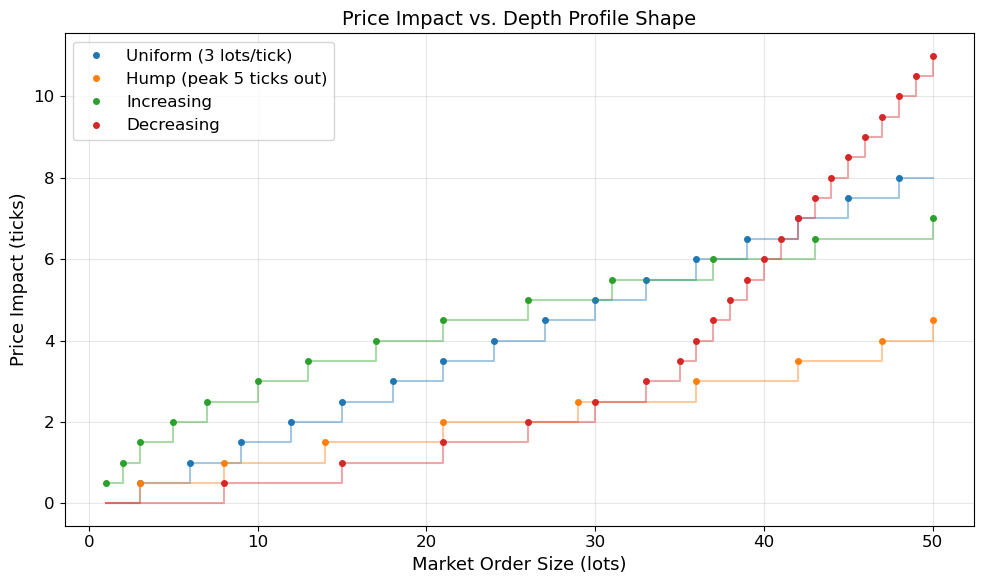


Impact follows the depth profile: increasing depth gives concave impact, uniform depth linear impact, decreasing depth convex impact.
A hump-shaped profile, the shape reported for real markets, gives concave impact only for orders that stay in front of its peak. A static book alone cannot produce a square-root law that holds across order sizes.


In [5]:
def measure_impact(depth_fn, max_size=50, mid=10000):
    """Mid-price impact of buy market orders of sizes 1..max_size on a fresh book."""
    sizes, impacts = [], []
    for size in range(1, max_size + 1):
        reset_order_id_counter()
        book, engine = OrderBook(), PriceTimeEngine()
        for i in range(1, 100):
            for _ in range(depth_fn(i)):
                book.add_order(limit_order(mid + i, 1, 0.0, Side.ASK))
                book.add_order(limit_order(mid - i, 1, 0.0, Side.BID))
        before = book.mid_price
        engine.process(book, market_order(size=size, timestamp=1.0, side=Side.BID))
        sizes.append(size)
        impacts.append(book.mid_price - before)
    return np.array(sizes), np.array(impacts)


profiles = {
    'Uniform (3 lots/tick)': lambda i: 3,
    'Hump (peak 5 ticks out)': lambda i: max(1, int(8 * np.exp(-0.05 * (i - 5) ** 2))),
    'Increasing': lambda i: max(1, i // 2),
    'Decreasing': lambda i: max(1, 9 - i),
}

def shape_of(slope):
    if np.isnan(slope):
        return 'undetermined'
    return 'concave' if slope < 0.95 else 'convex' if slope > 1.05 else 'roughly linear'

fig, ax = plt.subplots(figsize=(10, 6))
shapes = {}
for name, depth_fn in profiles.items():
    s, imp = measure_impact(depth_fn)
    corner = np.diff(np.concatenate([[0.0], imp])) > 0  # sizes that exactly clear a level
    lines = ax.step(s, imp, where='post', alpha=0.4)
    ax.plot(s[corner], imp[corner], 'o', markersize=4, color=lines[0].get_color(), label=name)
    s, imp = s[corner], imp[corner]
    slope = fit_loglog_slope(s, imp)
    shapes[name] = shape_of(slope)
    line = f"{name}: log-log slope {slope:.2f} over 1-50 lots -> {shapes[name]}"
    if name.startswith('Hump'):
        peak_level = 1 + int(np.argmax([depth_fn(i) for i in range(1, 100)]))
        through_peak = sum(depth_fn(i) for i in range(1, peak_level + 1))
        before_peak = s <= through_peak
        inner = fit_loglog_slope(s[before_peak], imp[before_peak])
        outer = fit_loglog_slope(s[~before_peak], imp[~before_peak])
        shapes['hump, up to the peak'], shapes['hump, past the peak'] = shape_of(inner), shape_of(outer)
        line += (f" (orders up to the {through_peak} lots in front of and at the peak: {inner:.2f}, "
                 f"{shape_of(inner)}; larger orders: {outer:.2f}, {shape_of(outer)})")
    print(line)
    findings.append(line)

ax.set_xlabel('Market Order Size (lots)')
ax.set_ylabel('Price Impact (ticks)')
ax.set_title('Price Impact vs. Depth Profile Shape')
ax.legend()
plt.tight_layout()
plt.show()

if (shapes['Increasing'], shapes['Uniform (3 lots/tick)'], shapes['Decreasing']) == (
        'concave', 'roughly linear', 'convex'):
    print("\nImpact follows the depth profile: increasing depth gives concave impact, "
          "uniform depth linear impact, decreasing depth convex impact.")
if (shapes['hump, up to the peak'], shapes['hump, past the peak']) == ('concave', 'convex'):
    print("A hump-shaped profile, the shape reported for real markets, gives concave impact only for "
          "orders that stay in front of its peak. A static book alone cannot produce a square-root law "
          "that holds across order sizes.")

## Question 4: Feedback Between Price Moves and Liquidity

From the paper (Section 3.3): *"In addition to traders' actions depending on L(t), the state of L(t) also clearly depends on traders' actions. These mutual dependences induce feedback."*

Question 1 tested feedback within the order flow (market orders triggering market orders). Here we test feedback from prices to liquidity. **Experiment:** let liquidity react to price moves. Whenever the mid-price has moved since the previous event, the model queues cancellations and submits them, as ordinary cancel events, before any new order flow. We compare two reactions:

- **Stale-order cleanup:** cancel up to five orders more than 10 ticks from the new mid-price.
- **Withdrawal at the quotes:** cancel the front order at each best quote. These cancellations can themselves move the mid-price, so this rule can feed on itself.

In [6]:
class ZIWithFeedback(SmithFarmerModel):
    """ZI model whose resting liquidity reacts to mid-price moves."""

    def __init__(self, rule, **kwargs):
        super().__init__(**kwargs)
        self.rule = rule
        self._prev_mid = None
        self._pending = deque()
        self.feedback_cancels = 0

    def _queue_reaction(self, book, mid):
        if self.rule == 'stale':
            far = [oid for oid in book.all_order_ids() if abs(book.get_order(oid).price - mid) > 10]
            self._pending.extend(far[:5])
        else:
            for price, side in ((book.best_bid, Side.BID), (book.best_ask, Side.ASK)):
                if price is not None:
                    self._pending.append(book.orders_at(price, side)[0].order_id)

    def generate_event(self, book, t, rng):
        mid = book.mid_price
        if mid is not None and self._prev_mid is not None and mid != self._prev_mid:
            self._queue_reaction(book, mid)
        if mid is not None:
            self._prev_mid = mid
        while self._pending:
            order_id = self._pending.popleft()
            if book.get_order(order_id) is not None:
                self._t = max(self._t, t)
                self.feedback_cancels += 1
                return cancel_order(order_id, timestamp=self._t)
        return super().generate_event(book, t, rng)


def feedback_share(model, df):
    return {'feedback cancels (share of events)': model.feedback_cancels / len(df)}


feedback = {
    'Baseline ZI': [dict(r, **{'feedback cancels (share of events)': 0.0}) for r in ablation['Baseline ZI']],
    'Stale-order cleanup': run_variant(lambda: ZIWithFeedback('stale', **ZI_PARAMS), feedback_share),
    'Withdrawal at the quotes': run_variant(lambda: ZIWithFeedback('withdraw', **ZI_PARAMS), feedback_share),
}
display(table(feedback, ['mean spread', 'excess kurtosis', 'rank ACF of |r|, lag 1', 'ACF of r, lag 1',
                         'feedback cancels (share of events)']))

,mean spread,excess kurtosis,"rank ACF of |r|, lag 1","ACF of r, lag 1",feedback cancels (share of events)
Baseline ZI,1.321 ± 0.004,0.232 ± 0.118,0.030 ± 0.016,-0.161 ± 0.010,0.000 ± 0.000
Stale-order cleanup,1.346 ± 0.004,0.423 ± 0.073,0.055 ± 0.016,-0.133 ± 0.018,0.035 ± 0.000
Withdrawal at the quotes,25.791 ± 0.074,1.921 ± 0.676,0.129 ± 0.045,0.166 ± 0.048,0.492 ± 0.000


In [7]:
print("Relative to the baseline ZI model:")
for column, label in (('mean spread', 'mean spread'),
                      ('excess kurtosis', 'excess kurtosis'),
                      ('rank ACF of |r|, lag 1', 'volatility clustering (rank ACF)'),
                      ('ACF of r, lag 1', 'lag-1 return autocorrelation')):
    findings += compare(feedback, 'Baseline ZI', column, label)

Relative to the baseline ZI model:
Stale-order cleanup raises the mean spread (+0.025 ± 0.006)
Withdrawal at the quotes raises the mean spread (+24.469 ± 0.074)
Stale-order cleanup does not significantly change the excess kurtosis (+0.192 ± 0.138)
Withdrawal at the quotes tentatively raises the excess kurtosis (+1.689 ± 0.686)
Stale-order cleanup does not significantly change the volatility clustering (rank ACF) (+0.026 ± 0.023)
Withdrawal at the quotes tentatively raises the volatility clustering (rank ACF) (+0.099 ± 0.048)
Stale-order cleanup does not significantly change the lag-1 return autocorrelation (+0.028 ± 0.021)
Withdrawal at the quotes raises the lag-1 return autocorrelation (+0.327 ± 0.049)


## Summary

Every conclusion below was computed in this notebook; rerunning it with other seeds or parameters regenerates them.

In [8]:
for line in findings:
    print("-", line)

- + Heavy sizes raises the excess kurtosis (+2.423 ± 0.548)
- + Long-memory signs does not significantly change the excess kurtosis (+0.248 ± 0.156)
- + Self-exciting market orders raises the excess kurtosis (+4.556 ± 0.837)
- + Heavy sizes does not significantly change the volatility clustering (rank ACF) (+0.013 ± 0.029)
- + Long-memory signs does not significantly change the volatility clustering (rank ACF) (+0.011 ± 0.021)
- + Self-exciting market orders raises the volatility clustering (rank ACF) (+0.223 ± 0.022)
- Order splitting with power-law run lengths produces long memory close to the theory: ACF slope -0.43 vs -0.50, R/S H 0.83 vs 0.75
- Uniform (3 lots/tick): log-log slope 1.00 over 1-50 lots -> roughly linear
- Hump (peak 5 ticks out): log-log slope 0.76 over 1-50 lots -> concave (orders up to the 29 lots in front of and at the peak: 0.71, concave; larger orders: 1.20, convex)
- Increasing: log-log slope 0.63 over 1-50 lots -> concave
- Decreasing: log-log slope 1.81 over

These experiments show how simulation can test hypotheses about market microstructure without real data: isolate one mechanism, hold everything else fixed, replicate across seeds, and let the measurements decide.